In [1]:
#| label: setup
import math
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from latincyreaders import TesseraeReader

CR = TesseraeReader()
FILES = sorted(f for f in CR.fileids() if "vergil." in f)
print(f"{len(FILES)} files of Vergil")
print([Path(f).stem for f in FILES])

17 files of Vergil
['vergil.aeneid.part.1', 'vergil.aeneid.part.10', 'vergil.aeneid.part.11', 'vergil.aeneid.part.12', 'vergil.aeneid.part.2', 'vergil.aeneid.part.3', 'vergil.aeneid.part.4', 'vergil.aeneid.part.5', 'vergil.aeneid.part.6', 'vergil.aeneid.part.7', 'vergil.aeneid.part.8', 'vergil.aeneid.part.9', 'vergil.eclogues', 'vergil.georgics.part.1', 'vergil.georgics.part.2', 'vergil.georgics.part.3', 'vergil.georgics.part.4']


⟦LLM-DRAFT⟧ Note one difference from 2017 immediately. The Latin Library split
the *Eclogues* into ten files, so the old notebook worked with 26 texts and
treated each eclogue as a unit. Tesserae keeps the *Eclogues* as one file, giving
17. That is not a defect; it is a reminder that "how many texts are there" is a
decision the corpus makes for you, and it silently changes every per-text average
you compute.

## The syllable counter, and a way to check it

⟦LLM-DRAFT⟧ The 2017 notebook patched its syllable counter with substitutions —
`qu`→`qv`, and `ae`/`oe`/`ei`→`e` — and then had no way to find out whether the
patch worked. Here is the counter from the Cicero post, which handles consonantal
`v`, `j`, and intervocalic `i`.

In [2]:
#| label: syllables
VOWELS = "aeiouy"
DIPHTHONGS = ("ae", "oe", "au", "eu", "ei", "ui")


def phon(word):
    """Lower-case and strip non-letters, keeping v/j as consonants."""
    return re.sub(r"[^a-z]", "", word.lower())


def mark_consonantal_i(w):
    """Rewrite consonantal i as j so it is not counted as a nucleus."""
    if len(w) > 1 and w[0] == "i" and w[1] in VOWELS:
        w = "j" + w[1:]
    return re.sub(r"(?<=[aeiouy])i(?=[aeiouy])", "j", w)


def count_syllables(word):
    w = mark_consonantal_i(phon(word))
    if not w:
        return 0
    w = re.sub(r"(?<=[qg])u(?=[aeiouy])", "", w)
    count, i = 0, 0
    while i < len(w):
        if w[i] in VOWELS:
            i += 2 if w[i : i + 2] in DIPHTHONGS else 1
            count += 1
        else:
            i += 1
    return count

⟦LLM-DRAFT⟧ Poetry adds elision: a word ending in a vowel, a diphthong, or a
vowel plus `m` loses that syllable before a word beginning with a vowel or `h`.
Prose readability formulas have no concept of this, which is already a sign that
they were not built for verse.

In [3]:
#| label: elision
def elided_syllables(line):
    """Syllable count for a verse line, applying elision."""
    words = [w for w in (phon(x) for x in re.findall(r"[a-zA-Z]+", line)) if w]
    if not words:
        return 0
    total = sum(count_syllables(w) for w in words)
    elisions = 0
    for first, second in zip(words, words[1:]):
        ends_open = first[-1] in VOWELS or (
            len(first) > 1 and first[-1] == "m" and first[-2] in VOWELS
        )
        nxt = mark_consonantal_i(second)      # iam does not admit elision
        starts_open = nxt[0] in VOWELS or nxt[0] == "h"
        elisions += ends_open and starts_open
    return total - elisions


for line in [
    "Arma virumque cano, Troiae qui primus ab oris",
    "litora, multum ille et terris iactatus et alto",
]:
    raw = sum(count_syllables(w) for w in re.findall(r"[a-zA-Z]+", line))
    print(f"{elided_syllables(line):2d} (raw {raw:2d})  {line}")

15 (raw 15)  Arma virumque cano, Troiae qui primus ab oris
14 (raw 16)  litora, multum ille et terris iactatus et alto


## Ground truth: every hexameter has 12 to 17 syllables

⟦LLM-DRAFT⟧ Here is the check that the prose corpus could not give us. A
dactylic hexameter has six feet; the first five are each a dactyl (three
syllables) or a spondee (two), and the sixth is always two. So a correctly
counted line must fall between 12 and 17 syllables. No metrical analysis
required — just a range, and 9,896 chances to fall outside it.

In [4]:
#| label: hexameter-validation
TESS = Path.home() / "latincy_data" / "lat_text_tesserae" / "texts"
CITED = re.compile(r"<([^>]+)>\s*(.+)")

rows = []
for p in sorted(TESS.glob("vergil.aeneid.part.*.tess")):
    for line in p.read_text().splitlines():
        m = CITED.match(line)
        if not m:
            continue
        cit, txt = m.group(1), m.group(2)
        n = elided_syllables(txt)
        if n == 0:
            continue
        rows.append({
            "citation": cit,
            "text": txt,
            "syllables": n,
            "raw": sum(count_syllables(w) for w in re.findall(r"[a-zA-Z]+", txt)),
        })

aen = pd.DataFrame(rows)
in_range = aen["syllables"].between(12, 17)
raw_in_range = aen["raw"].between(12, 17)

print(f"Aeneid lines:                       {len(aen):,}")
print(f"in [12,17] with elision:            {in_range.sum():,} "
      f"({100*in_range.mean():.2f}%)")
print(f"in [12,17] without elision (2017):  {raw_in_range.sum():,} "
      f"({100*raw_in_range.mean():.2f}%)")

Aeneid lines:                       9,896
in [12,17] with elision:            9,836 (99.39%)
in [12,17] without elision (2017):  9,678 (97.80%)


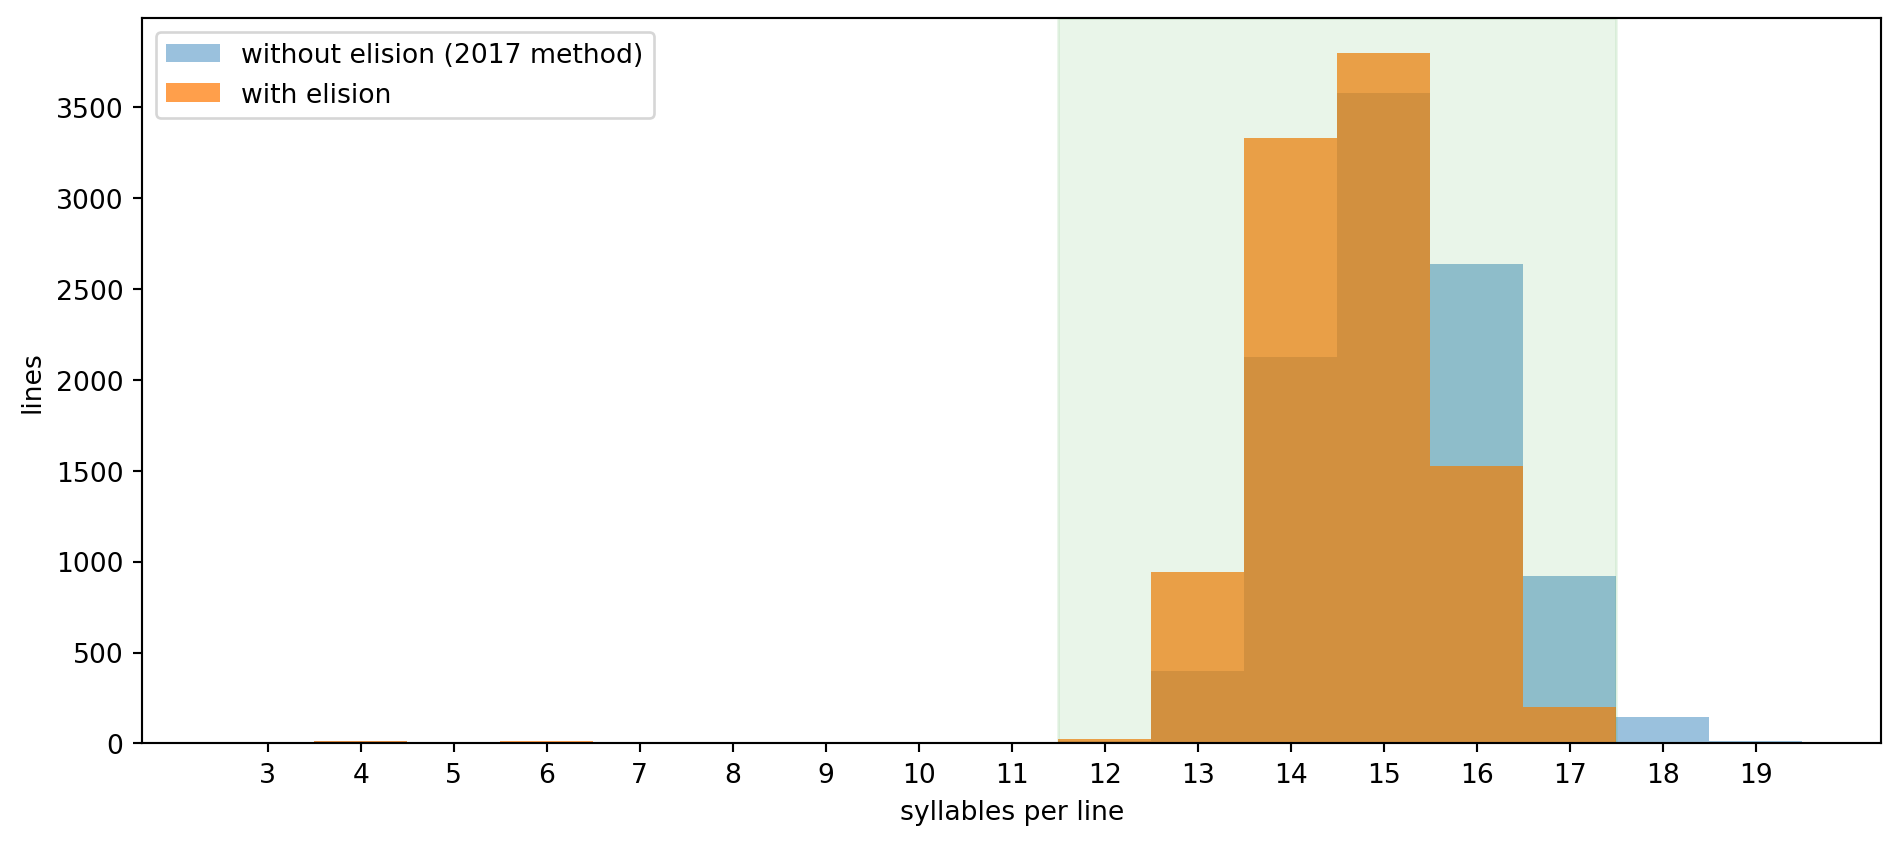

In [5]:
#| label: fig-syllable-dist
#| fig-cap: "Syllables per line of the *Aeneid*, with and without elision. The metrically possible band is shaded."
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.arange(2.5, 20.5, 1)
ax.hist(aen["raw"], bins=bins, alpha=0.45, label="without elision (2017 method)")
ax.hist(aen["syllables"], bins=bins, alpha=0.75, label="with elision")
ax.axvspan(11.5, 17.5, color="tab:green", alpha=0.10)
ax.set_xlabel("syllables per line")
ax.set_ylabel("lines")
ax.set_xticks(range(3, 20))
ax.legend()
fig.tight_layout()
plt.show()

In [6]:
#| label: failures
short = aen[aen["syllables"] < 12]
long_ = aen[aen["syllables"] > 17]
print(f"below 12: {len(short)}")
print(f"above 17: {len(long_)}")
print()
for _, r in long_.iterrows():
    print(f"  {r['citation']}  ({r['syllables']}) {r['text']}")

below 12: 58
above 17: 2

  verg. aen. 11.383  (18) Proinde tona eloquio, solitum tibi, meque timoris
  verg. aen. 3.331  (18) coniugis et scelerum Furiis agitatus, Orestes


In [7]:
#| label: tbl-halflines
#| tbl-cap: "A sample of the short lines. These are not counting errors."
short[["citation", "syllables", "text"]].head(10)

,citation,syllables,text
533,verg. aen. 1.534,4,Hic cursus fuit:
559,verg. aen. 1.560,4,Dardanidae.
635,verg. aen. 1.636,10,munera laetitiamque dii.
772,verg. aen. 10.17,4,pauca refert:
1039,verg. aen. 10.284,8,"Audentis Fortuna iuvat,"""
1245,verg. aen. 10.490,8,"Quem Turnus super adsistens,"
1335,verg. aen. 10.580,3,Cui Liger:
1483,verg. aen. 10.728,4,"ora cruor,"
1631,verg. aen. 10.876,9,"incipias conferre manum."""
2038,verg. aen. 11.375,3,"qui vocat."""


⟦LLM-DRAFT⟧ This is the result worth pausing on. The counter falls outside the
metrical range 60 times in 9,896 lines. Fifty-eight of those are *short* — and
they are not errors at all. They are Vergil's incomplete lines, the *tibicines*
that he left unfinished at his death, whose canonical count is likewise 58. The
method rediscovers them without being told they exist.

That leaves exactly two genuine over-counts, and both are explicable. At *Aen.*
11.383 *Proinde* is scanned by synizesis as two syllables rather than three. At
*Aen.* 3.331 *coniugis* is `con-iu-gis`, a compound whose `i` is consonantal but
follows a consonant, so the intervocalic rule cannot see it — the known
limitation, documented in the function itself.

Two errors in 9,896 lines is a defensible error rate, and — more to the point —
it is a *measured* one. The 2017 version had no way to know.

## 100-word samples

⟦LLM-DRAFT⟧ Following the 2017 notebook, and Clymer [@clymer-1959] and Spache
[@spache-1978] behind it, the analysis works on 100-word samples rather than
whole books. Sampling was originally a way to make hand-counting affordable; it
survives because a single score for all twelve books of the *Aeneid* hides more
than it shows.

In [8]:
#| label: wordlists
def normalize_lemma(text):
    """Fold to the u/i orthography of latincy-words. LOOKUP ONLY."""
    return text.lower().replace("j", "i").replace("v", "u")


DCC = {
    normalize_lemma(line.strip())
    for line in Path("dcc-core-vocab.txt").read_text().splitlines()
    if line.strip() and not line.startswith("#")
}

LEMMA_RANK = {}
with open("latin-lemma-ranks.tsv") as f:
    next(f)
    for line in f:
        rank, lemma = line.rstrip("\n").split("\t")
        LEMMA_RANK.setdefault(normalize_lemma(lemma), int(rank))

print(f"DCC core lemmas: {len(DCC)}  |  ranked lemmas: {len(LEMMA_RANK):,}")

DCC core lemmas: 959  |  ranked lemmas: 49,560


In [9]:
#| label: formulas
def ari(c, w, s):
    return 4.71 * (c / w) + 0.5 * (w / s) - 21.43


def gunning_fog(w, s, cw):
    return 0.4 * ((w / s) + 100 * (cw / w))


def flesch_kincaid(w, s, sy):
    return 0.39 * (w / s) + 11.8 * (sy / w) - 15.59


def coleman_liau(c, w, s):
    return 0.0588 * (c / w * 100) - 0.296 * (s / w * 100) - 15.8


def dale_chall(w, s, dw):
    return 0.1579 * (dw / w * 100) + 0.0496 * (w / s)


CONTENT_POS = {"NOUN", "PROPN", "VERB", "ADJ", "ADV"}


def mattr(tokens, window=50):
    if len(tokens) <= window:
        return len(set(tokens)) / len(tokens) if tokens else 0.0
    counts = Counter(tokens[:window])
    total, n = len(counts) / window, 1
    for i in range(window, len(tokens)):
        out, inc = tokens[i - window], tokens[i]
        counts[out] -= 1
        if not counts[out]:
            del counts[out]
        counts[inc] += 1
        total += len(counts) / window
        n += 1
    return total / n

In [10]:
#| label: build
CACHE = Path("vergil-segments.csv")


def work_label(fileid):
    stem = Path(fileid).stem.replace("vergil.", "")
    parts = stem.split(".part.")
    name = {"aeneid": "Aen.", "eclogues": "Ecl.", "georgics": "Geo."}[parts[0]]
    return f"{name} {parts[1]}" if len(parts) > 1 else name


def segment_sentences(sents, target=100):
    """Group consecutive sentences into ~`target`-word samples."""
    chunk, words = [], 0
    for sent in sents:
        chunk.append(sent)
        words += sum(1 for t in sent if t.is_alpha)
        if words >= target:
            yield chunk
            chunk, words = [], 0
    if words >= target // 2:
        yield chunk


def measure(sents):
    chars = words = syls = complex_words = n_sents = 0
    tokens, lemmas, content = [], [], 0
    for sent in sents:
        n_sents += 1
        for tok in sent:
            if not tok.is_alpha:
                continue
            words += 1
            chars += len(tok.text)
            s = count_syllables(tok.text)
            syls += s
            complex_words += s > 3
            tokens.append(normalize_lemma(tok.text))
            lemmas.append(normalize_lemma(tok.lemma_))
            content += tok.pos_ in CONTENT_POS
    if not words:
        return None
    ranks = [LEMMA_RANK.get(lm) for lm in lemmas]
    known = [r for r in ranks if r]
    difficult = sum(1 for lm in lemmas if lm not in DCC)
    return {
        "words": words, "sents": n_sents,
        "ari": ari(chars, words, n_sents),
        "fog": gunning_fog(words, n_sents, complex_words),
        "fk": flesch_kincaid(words, n_sents, syls),
        "cl": coleman_liau(chars, words, n_sents),
        "dc": dale_chall(words, n_sents, difficult),
        "word_length": chars / words,
        "mean_log_rank": (sum(math.log10(r) for r in known) / len(known)) if known else 0.0,
        "sophistication": sum(1 for r in ranks if r is None or r > 1000) / words,
        "density": content / words,
        "variation": mattr(tokens),
    }


def citations(span_start, span_end, lines):
    return [l._.citation for l in lines
            if l.start < span_end and l.end > span_start]


if CACHE.exists():
    segs = pd.read_csv(CACHE)
else:
    rows = []
    for fid in FILES:
        doc = next(iter(CR.docs([fid])))
        lines = list(doc.spans["lines"])
        label = work_label(fid)
        for i, chunk in enumerate(segment_sentences(doc.sents)):
            m = measure(chunk)
            if not m:
                continue
            cits = citations(chunk[0].start, chunk[-1].end, lines)
            m.update({
                "work": label,
                "segment": f"{label}_{i}",
                "citation_first": cits[0] if cits else "",
                "citation_last": cits[-1] if cits else "",
                "text": " ".join(" ".join(s.text for s in chunk).split()),
            })
            rows.append(m)
    segs = pd.DataFrame(rows)
    segs.to_csv(CACHE, index=False)

print(f"{len(segs)} samples across {segs['work'].nunique()} works")
segs[["segment", "words", "sents", "ari", "dc"]].head()

795 samples across 17 works


,segment,words,sents,ari,dc
0,Aen. 1_0,106,6,12.552956,6.238908
1,Aen. 1_1,113,8,10.516305,5.591308
2,Aen. 1_2,102,7,11.345126,7.534115
3,Aen. 1_3,109,7,12.239109,7.146288
4,Aen. 1_4,117,7,11.765348,6.497234


## What the formulas see in verse

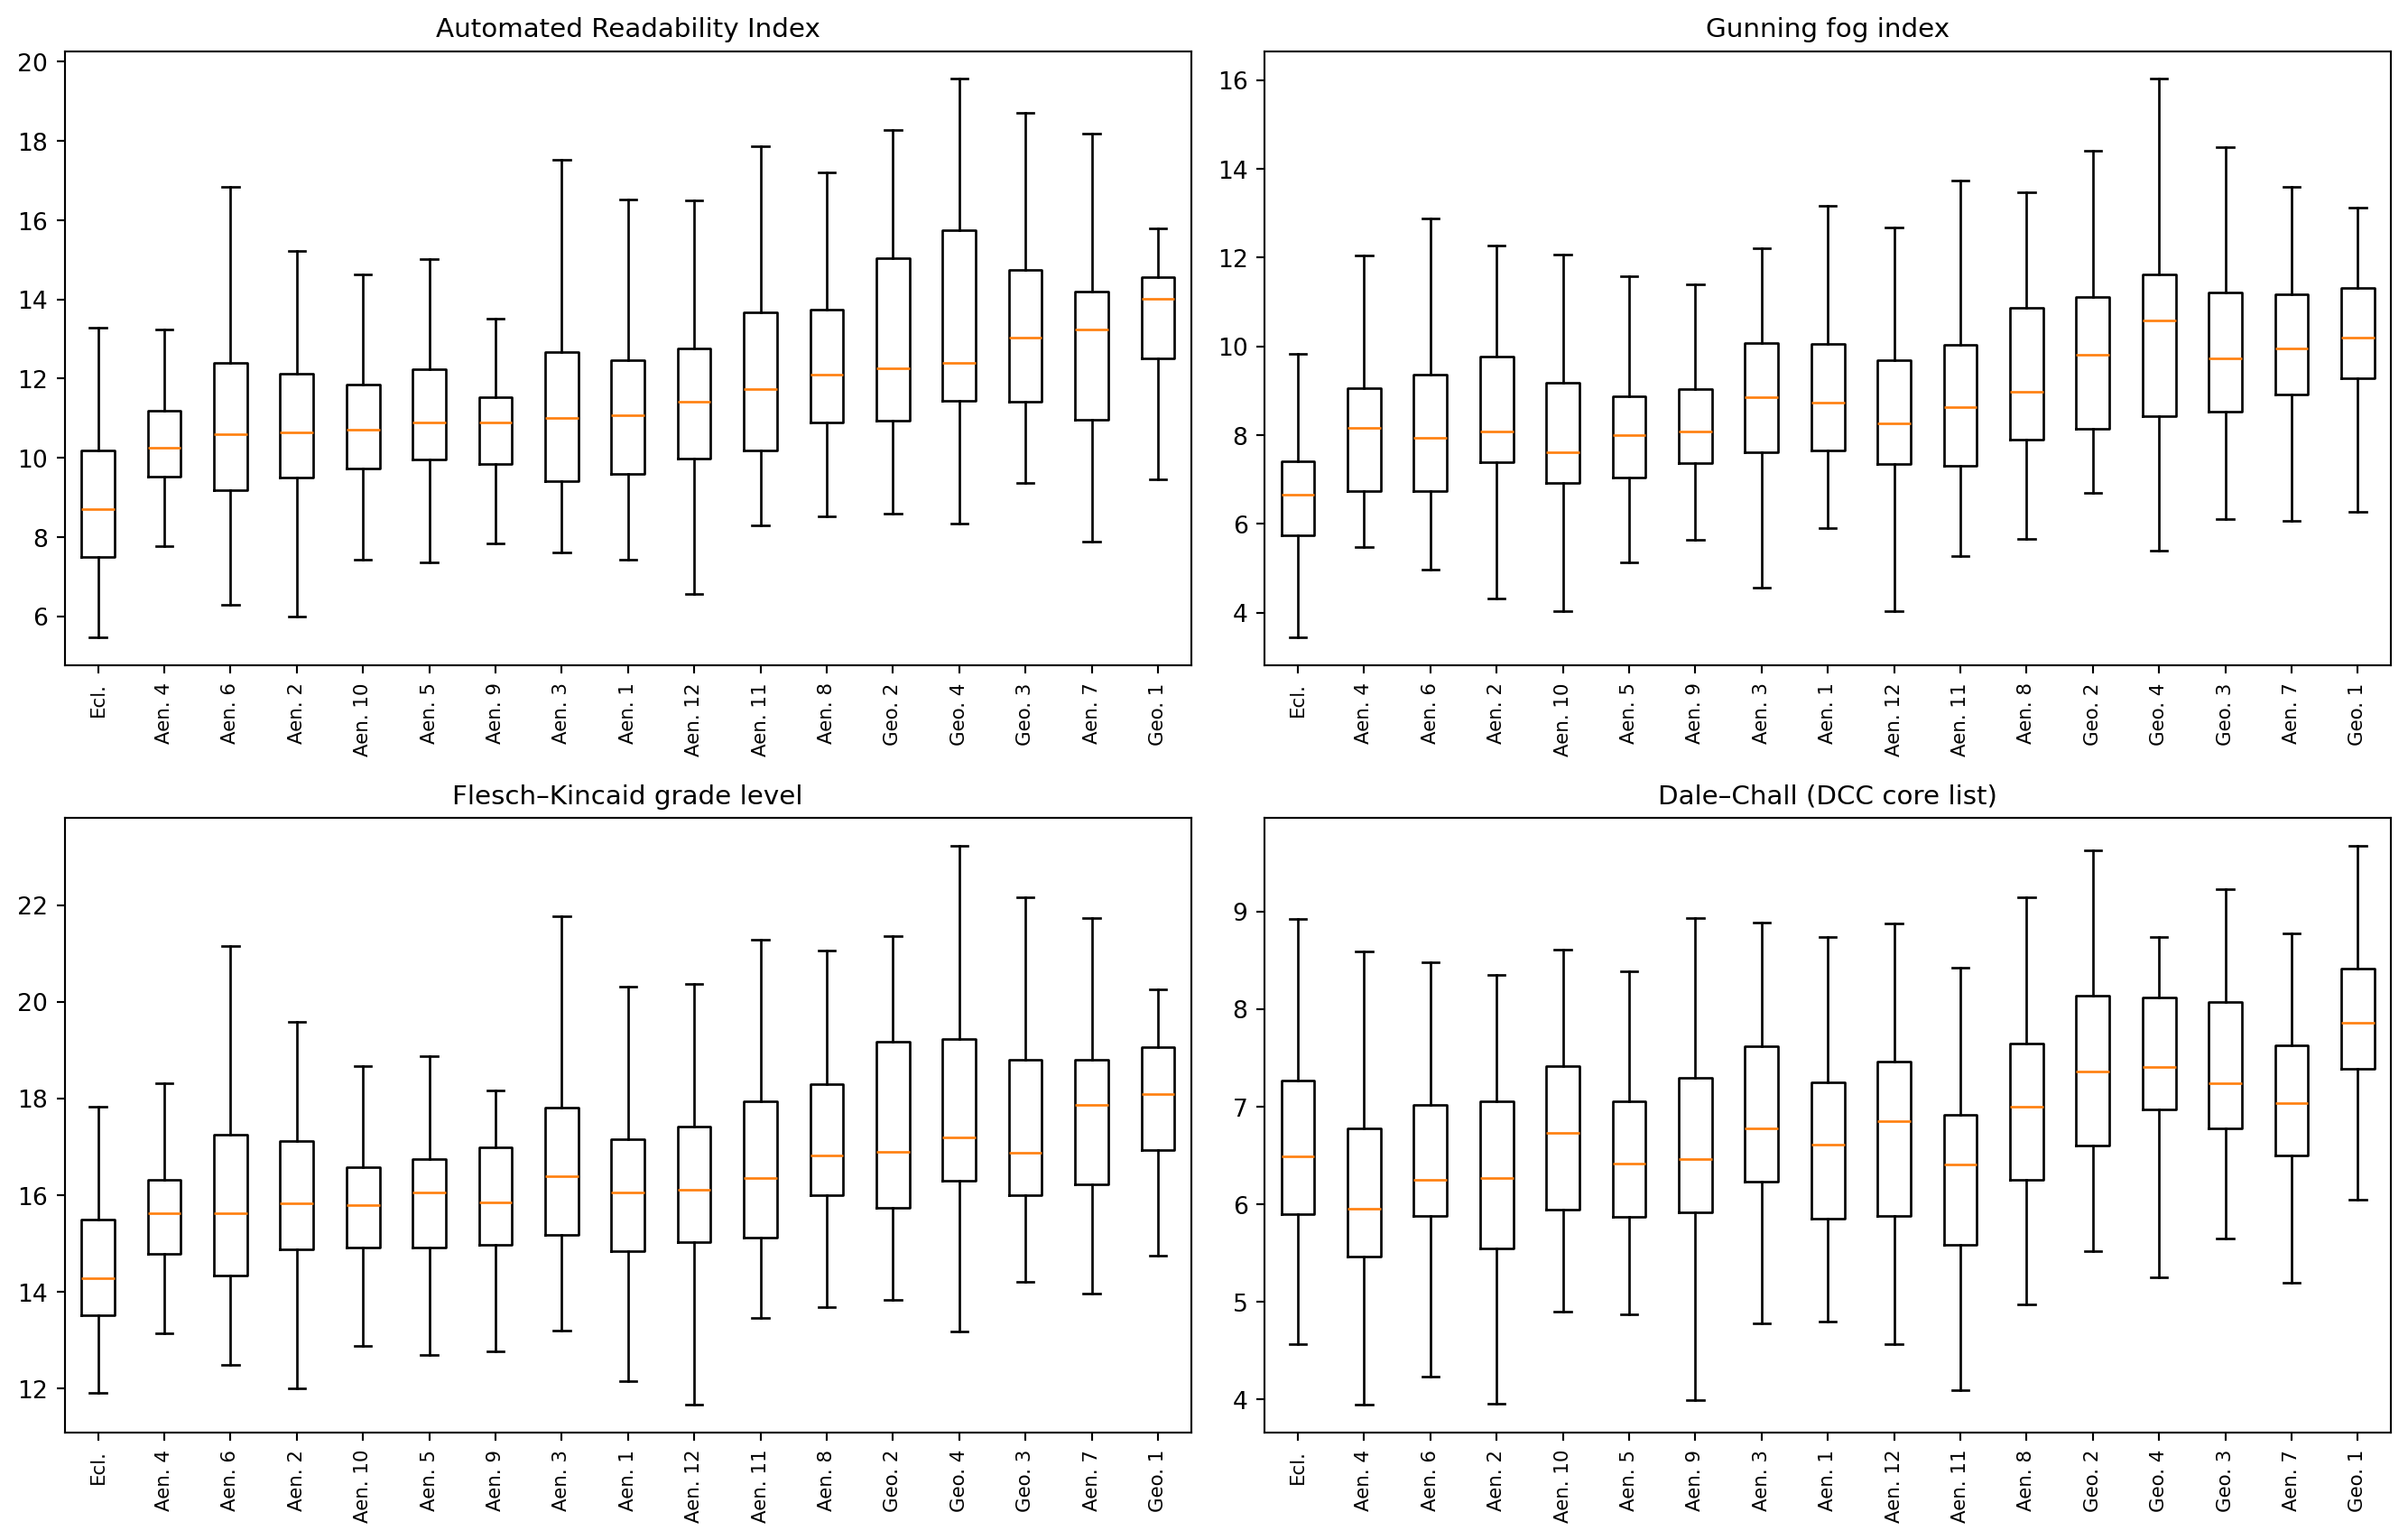

In [11]:
#| label: fig-by-work
#| fig-cap: "Distribution of readability scores across 100-word samples, by work."
TESTS = [("ari", "Automated Readability Index"),
         ("fog", "Gunning fog index"),
         ("fk", "Flesch–Kincaid grade level"),
         ("dc", "Dale–Chall (DCC core list)")]

order = (segs.groupby("work")["ari"].median().sort_values().index.tolist())
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (col, label) in zip(axes.flat, TESTS):
    data = [segs.loc[segs["work"] == w, col].values for w in order]
    ax.boxplot(data, tick_labels=order, showfliers=False)
    ax.set_title(label, fontsize=11)
    ax.tick_params(axis="x", rotation=90, labelsize=8)
fig.tight_layout()
plt.show()

In [12]:
#| label: tbl-sentence-length
#| tbl-cap: "Words per sentence by work — the variable every formula leans on hardest."
(segs.assign(wps=segs["words"] / segs["sents"])
     .groupby("work")
     .agg(samples=("segment", "count"),
          words_per_sentence=("wps", "mean"),
          ari=("ari", "mean"),
          sophistication=("sophistication", "mean"))
     .sort_values("words_per_sentence")
     .round(2))

,samples,words_per_sentence,ari,sophistication
work,,,,
Ecl.,53,10.27,8.93,0.42
Aen. 4,44,12.51,10.45,0.42
Aen. 3,44,12.82,11.25,0.47
Aen. 10,57,12.86,10.89,0.45
Aen. 2,50,12.92,10.81,0.43
Aen. 5,54,13.08,11.10,0.44
Aen. 9,50,13.10,10.93,0.44
Aen. 6,55,13.45,11.03,0.42
Aen. 1,47,14.18,11.28,0.43


In [13]:
#| label: tbl-what-they-measure
#| tbl-cap: "Spearman correlation of each measure with words per sentence, across all 795 samples."
segs["wps"] = segs["words"] / segs["sents"]
COLS = ["ari", "fog", "fk", "cl", "dc",
        "sophistication", "variation", "word_length"]
pd.DataFrame({
    "vs. words-per-sentence": [segs[c].corr(segs["wps"], method="spearman")
                               for c in COLS]
}, index=COLS).round(3).sort_values("vs. words-per-sentence", ascending=False)

,vs. words-per-sentence
ari,0.901
fk,0.850
fog,0.833
cl,0.569
dc,0.400
sophistication,0.220
word_length,0.156
variation,-0.178


In [14]:
#| label: tbl-inter-formula
#| tbl-cap: "How much the measures agree with each other (Spearman)."
segs[["ari", "fog", "fk", "cl", "dc", "sophistication"]].corr(method="spearman").round(2)

,ari,fog,fk,cl,dc,sophistication
ari,1.00,0.87,0.96,0.85,0.57,0.42
fog,0.87,1.00,0.89,0.68,0.41,0.24
fk,0.96,0.89,1.00,0.83,0.56,0.40
cl,0.85,0.68,0.83,1.00,0.62,0.55
dc,0.57,0.41,0.56,0.62,1.00,0.83
sophistication,0.42,0.24,0.40,0.55,0.83,1.00


⟦LLM-DRAFT⟧ These two tables are the real argument of both posts. ARI correlates
with words-per-sentence at ρ = 0.90, Flesch–Kincaid at 0.85, Gunning fog at 0.83;
and ARI and Flesch–Kincaid agree with *each other* at 0.96. Running four
formulas here is close to running one formula four times. Lexical
sophistication, by contrast, barely tracks sentence length at all (0.22) and
sits at 0.83 with Dale–Chall — the two measures that actually look at which
words are on the page.

So if a teacher asks which of two passages is harder, the classic formulas
answer a narrower question than they appear to: which has the longer sentences.
That is worth knowing, and it is not nothing — but it is not vocabulary, and
vocabulary is what the research since 2016 says matters most
[@gruber-miller-mulligan-2022].

⟦LLM-DRAFT⟧ There is a further wrinkle specific to verse: sentence length here is
not measuring what it measures in prose. A Vergilian period runs across line-ends, and the
sentence boundaries LatinCy finds are the editor's punctuation — which in a
verse text is a modern editorial overlay on a tradition that did not punctuate.
So "words per sentence," the variable that dominates ARI, fog, and
Flesch–Kincaid alike, is in verse partly a measurement of an editor.

That is not an argument against measuring. It is an argument for knowing which
of your variables are properties of the text and which are properties of the
edition — and it is precisely the sort of thing the newer Latin-specific work
[@laurs-2024] is positioned to handle better than a formula ported from English.

## Vergil's hardest line

In [15]:
#| label: hardest-line
line_rows = []
for _, r in aen.iterrows():
    words = re.findall(r"[a-zA-Z]+", r["text"])
    if len(words) < 5:
        continue
    chars = sum(len(w) for w in words)
    lemmas = [normalize_lemma(w) for w in words]
    line_rows.append({
        "citation": r["citation"],
        "text": r["text"],
        "words": len(words),
        "syllables": r["syllables"],
        "chars_per_word": chars / len(words),
        "out_of_core": sum(1 for lm in lemmas if lm not in DCC) / len(words),
    })

lines_df = pd.DataFrame(line_rows)
lines_df["score"] = (
    (lines_df["chars_per_word"] - lines_df["chars_per_word"].mean())
    / lines_df["chars_per_word"].std()
    + (lines_df["out_of_core"] - lines_df["out_of_core"].mean())
    / lines_df["out_of_core"].std()
)
top = lines_df.sort_values("score", ascending=False).head(10)
top[["citation", "words", "chars_per_word", "out_of_core", "text"]].round(2)

,citation,words,chars_per_word,out_of_core,text
754,verg. aen. 10.4,5,9.0,1.0,castraque Dardanidum adspectat populosque Lati...
1143,verg. aen. 10.396,5,8.8,1.0,semianimesque micant digiti ferrumque retractant.
2646,verg. aen. 12.85,5,8.8,1.0,Circumstant properi aurigae manibusque lacessunt
2262,verg. aen. 11.614,5,8.8,1.0,dant sonitum ingenti perfractaque quadrupedantum
9348,verg. aen. 9.344,5,8.6,1.0,"Fadumque Herbesumque subit Rhoetumque Abarimque,"
7133,verg. aen. 6.559,5,8.6,1.0,"Constitit Aeneas, strepitumque exterritus hausit."
3234,verg. aen. 12.675,5,8.6,1.0,subdideratque rotas pontisque instraverat altos.
5156,verg. aen. 4.146,5,8.6,1.0,Cretesque Dryopesque fremunt pictique Agathyrsi;
7970,verg. aen. 7.501,5,8.6,1.0,successitque gemens stabulis questuque cruentus
4270,verg. aen. 2.770,5,8.6,1.0,nequiquam ingeminans iterumque iterumque vocavi.


⟦LLM-DRAFT⟧ A caution about this table, which is why it is not called an ARI
ranking. Applied to a single hexameter, the prose formulas degenerate: with the
sentence count pinned to one, ARI becomes a function of word length and line
length only, and it will reliably hand you whichever line has the longest words.
The composite above at least says what it is measuring — long words that are not
in the DCC core list.

The honest answer to "Vergil's hardest line" is that the question is not
well-posed at the level of the line, and that the 2017 talk's version of it was
broken in a more literal sense: the cell that was supposed to collect sentences
looped over the wrong variable and scored the same stale text every time.

## Where this leaves the project

⟦LLM-DRAFT⟧ Two conclusions from redoing both talks.

First, the tooling upgrade is not cosmetic. Real sentence segmentation, real
lemmatization, and citation-anchored results change what can be claimed. And the
syllable counter — the most boring component in the pipeline — turns out to be
checkable against the hexameter, which is the kind of validation the original
work simply could not perform.

Second, the 2016–17 wishlist has largely been filled by others, as the
[Cicero post](../cicero-readability/) sets out: criterion passages from Laurs
[@laurs-2025], graded lexical measures from Gruber-Miller and Mulligan
[@gruber-miller-mulligan-2022], and cultural-knowledge load from the CLQ work
[@burns-clq-2024]. The natural next step is not another English formula ported
to Latin, but scoring these texts against Laurs's Latin-fitted regression
[@laurs-2024] and seeing where it disagrees with everything above.

::: {.callout-note}
## Open items

- Synizesis (*Proinde*, *deinde*) and compound consonantal `i` (*coniugis*) are
  unhandled; both known over-count sources, two lines total in the *Aeneid*.
- Sentence boundaries in verse are editorial. Worth a separate post.
- The corpus swaps to `plaintext-ll` in the setup cell once those texts are ready.
:::